### Load Prop Drillings from local csv file

In [73]:
import pandas as pd

In [74]:
df = pd.read_csv('/content/prop-drillings-export.csv', sep='|', header='infer')
df.columns = df.columns.str.strip()
display(df.head())

,project,sloc,pure,depth,candidate,candidateContext,candidateComposition,sourceProp,pathHash,path
0,joplin,47341,1,2,1,1,0,themeId,6499639f52563b8ad78e3f53310141d5cd65b6ce57db1...,gui\WindowCommandsAndDialogs\WindowCommandsAn...
1,joplin,47341,0,1,1,1,0,windowId,74a45a33d461568674298be5cae26aa39dd188de248f9...,gui\Root.tsx:RootComponent>>>gui\NoteEditor\E...
2,joplin,47341,0,1,1,1,0,viewId,02bda45356f0402335467a965f2fe0e0be8401e3a4341...,gui\WindowCommandsAndDialogs\PluginDialogs.ts...
3,joplin,47341,1,1,1,1,0,html,02bda45356f0402335467a965f2fe0e0be8401e3a4341...,gui\WindowCommandsAndDialogs\PluginDialogs.ts...
4,joplin,47341,1,1,1,1,0,scripts,02bda45356f0402335467a965f2fe0e0be8401e3a4341...,gui\WindowCommandsAndDialogs\PluginDialogs.ts...


### Prop Drillings and Pure Prop Drillings per Project

In [75]:
def addRatioColumn(df, ratioName, partName, wholeName, wholeValue = None, accuracy = 1):
    df[ratioName] = df.apply(
        lambda row: round(row[partName] / row[wholeName] * 100, accuracy), axis=1)
    return df

# Group by 'project' and count occurrences
project_counts = df.groupby(['project', 'sloc']).size().reset_index(name='count')
project_counts.rename(columns={'count': 'propDrillings'}, inplace=True)
# sort by sloc descending
project_counts = project_counts.sort_values(by=['sloc'], ascending=False)
# Display the result
#display(project_counts.head())

# Pure prop drillings
# filter df by pure equals to true
ppd_df = df[df['pure'] == 1]
ppd_counts = ppd_df.groupby(['project', 'sloc']).size().reset_index(name='count')
ppd_counts.rename(columns={'count': 'purePropDrillings'}, inplace=True)
ppd_counts = ppd_counts.sort_values(by=['sloc'], ascending=False)
#display(ppd_counts.head())

# join df with ppd_df
project_all_counts = project_counts.merge(ppd_counts, on=['project', 'sloc'], how='inner')
project_all_counts  = project_all_counts.sort_values(by=['sloc'], ascending=False)
addRatioColumn(project_all_counts, 'purePercent', 'purePropDrillings', 'propDrillings')
# project_all_counts['purePercent'] = project_all_counts.apply(
#     lambda row: round( row['purePropDrillings'] / row['propDrillings'] * 100, 1),
#     axis = 1)

# Display the result
display(project_all_counts)

,project,sloc,propDrillings,purePropDrillings,purePercent
0,grafana,696744,1376,684,49.7
1,metabase,477532,1917,842,43.9
2,affine,231911,841,548,65.2
3,superset,205589,256,146,57.0
4,novu,170978,1334,654,49.0
5,lobe-chat,169644,141,134,95.0
6,plane,143712,14,6,42.9
7,Rocket.Chat,142439,430,154,35.8
8,cal.com,89443,48,15,31.2
9,mastodon,56721,219,102,46.6


In [76]:
# sum columns propDrillings and purePropDrillings of project_all_counts
total_prop_drillings = project_all_counts['propDrillings'].sum()
total_pure_prop_drillings = project_all_counts['purePropDrillings'].sum()
print('Total prop drillings: ', total_prop_drillings)
print('Total pure prop drillings: ', total_pure_prop_drillings)

Total prop drillings:  6794
Total pure prop drillings:  3403


### Prop Drilling Depth Distribution

In [77]:
import pandas as pd

# Function to get depth counts for a given condition
def get_depth_counts(dataframe, depth_condition, column_name):
    filtered_df = dataframe[depth_condition]
    counts = filtered_df.groupby(['project', 'sloc']).size().reset_index(name=column_name)
    return counts

def depthDistribution(df, baselineColumn):
  # Depth 1 counts
  depth1_counts = get_depth_counts(df, df['depth'] == 1, 'depth1')
  pd_depth_distr = project_all_counts.merge(depth1_counts, on=['project', 'sloc'], how='left').fillna(0)

  # Depth 2 counts
  depth2_counts = get_depth_counts(df, df['depth'] == 2, 'depth2')
  pd_depth_distr = pd_depth_distr.merge(depth2_counts, on=['project', 'sloc'], how='left').fillna(0)

  # Depth 3 counts
  depth3_counts = get_depth_counts(df, df['depth'] == 3, 'depth3')
  pd_depth_distr = pd_depth_distr.merge(depth3_counts, on=['project', 'sloc'], how='left').fillna(0)

  # Depth 4 or more counts
  depth4_plus_counts = get_depth_counts(df, df['depth'] >= 4, 'depth4_plus')
  pd_depth_distr = pd_depth_distr.merge(depth4_plus_counts, on=['project', 'sloc'], how='left').fillna(0)

  addRatioColumn(pd_depth_distr, 'Depth 1', 'depth1', baselineColumn)
  addRatioColumn(pd_depth_distr, '2', 'depth2', baselineColumn)
  addRatioColumn(pd_depth_distr, '3', 'depth3', baselineColumn)
  addRatioColumn(pd_depth_distr, '4+', 'depth4_plus', baselineColumn)
  # Display the updated DataFrame
  #display(pd_depth_distr)

  return pd_depth_distr[['project', 'Depth 1', '2', '3', '4+', 'depth1', 'depth2', 'depth3', 'depth4_plus']]

def ratio(part, whole, accuracy = 1):
  return round(part / whole * 100, accuracy)

pd_depth_distr = depthDistribution(df, 'propDrillings')

total_depth1 = pd_depth_distr['depth1'].sum()
total_depth2 = pd_depth_distr['depth2'].sum()
total_depth3 = pd_depth_distr['depth3'].sum()
total_depth4_plus = pd_depth_distr['depth4_plus'].sum()

new_row = pd.DataFrame([{'project': 'ALL',
                       'Depth 1': ratio(total_depth1, total_prop_drillings),
                       '2': ratio(total_depth2, total_prop_drillings),
                       '3': ratio(total_depth3, total_prop_drillings),
                       '4+': ratio(total_depth4_plus, total_prop_drillings),
                       'depth1': total_depth1, 'depth2': total_depth2, 'depth3': total_depth3, 'depth4_plus': total_depth4_plus}])
pd_depth_distr = pd.concat([pd_depth_distr, new_row], ignore_index=True)

display(pd_depth_distr)
# set index column project
pd_depth_distr_pivot = pd_depth_distr[['project', 'Depth 1', '2', '3', '4+']]

# append row
#pd_depth_distr_pivot.loc['Total'] = pd_depth_distr_pivot.sum()
# set index column project
pd_depth_distr_pivot = pd_depth_distr_pivot.set_index('project')
# display(pd_depth_distr_pivot)

,project,Depth 1,2,3,4+,depth1,depth2,depth3,depth4_plus
0,grafana,78.5,16.1,4.1,1.2,1080,222.0,57.0,17.0
1,metabase,71.5,19.0,5.8,3.7,1370,364.0,112.0,71.0
2,affine,83.0,14.4,2.5,0.1,698,121.0,21.0,1.0
3,superset,90.6,9.0,0.4,0.0,232,23.0,1.0,0.0
4,novu,75.4,18.5,5.5,0.5,1006,247.0,74.0,7.0
5,lobe-chat,75.2,17.0,5.7,2.1,106,24.0,8.0,3.0
6,plane,100.0,0.0,0.0,0.0,14,0.0,0.0,0.0
7,Rocket.Chat,75.3,18.8,4.0,1.9,324,81.0,17.0,8.0
8,cal.com,56.2,33.3,10.4,0.0,27,16.0,5.0,0.0
9,mastodon,94.1,5.9,0.0,0.0,206,13.0,0.0,0.0


### Pure Prop Drillings Depth Distribution

In [78]:
# Pure Prop Drillings Distribution
ppd_depth_distr = depthDistribution(ppd_df, 'purePropDrillings')

total_depth1 = ppd_depth_distr['depth1'].sum()
total_depth2 = ppd_depth_distr['depth2'].sum()
total_depth3 = ppd_depth_distr['depth3'].sum()
total_depth4_plus = ppd_depth_distr['depth4_plus'].sum()

new_row = pd.DataFrame([{'project': 'ALL',
                       'Depth 1': ratio(total_depth1, total_pure_prop_drillings),
                       '2': ratio(total_depth2, total_pure_prop_drillings),
                       '3': ratio(total_depth3, total_pure_prop_drillings),
                       '4+': ratio(total_depth4_plus, total_pure_prop_drillings),
                       'depth1': total_depth1, 'depth2': total_depth2, 'depth3': total_depth3, 'depth4_plus': total_depth4_plus}])
ppd_depth_distr = pd.concat([ppd_depth_distr, new_row], ignore_index=True)
display(ppd_depth_distr)
# display(pd_depth_distr)
# set index column project
ppd_depth_distr_pivot = ppd_depth_distr[['project', 'Depth 1', '2', '3', '4+']]

ppd_depth_distr_pivot = ppd_depth_distr_pivot.set_index('project')
#display(ppd_depth_distr_pivot)

,project,Depth 1,2,3,4+,depth1,depth2,depth3,depth4_plus
0,grafana,85.5,11.8,2.2,0.4,585,81.0,15.0,3.0
1,metabase,87.8,10.9,0.8,0.5,739,92.0,7.0,4.0
2,affine,90.3,9.1,0.5,0.0,495,50.0,3.0,0.0
3,superset,91.8,8.2,0.0,0.0,134,12.0,0.0,0.0
4,novu,87.8,11.0,1.2,0.0,574,72.0,8.0,0.0
5,lobe-chat,73.9,17.9,6.0,2.2,99,24.0,8.0,3.0
6,plane,100.0,0.0,0.0,0.0,6,0.0,0.0,0.0
7,Rocket.Chat,89.6,7.1,0.6,2.6,138,11.0,1.0,4.0
8,cal.com,86.7,13.3,0.0,0.0,13,2.0,0.0,0.0
9,mastodon,94.1,5.9,0.0,0.0,96,6.0,0.0,0.0


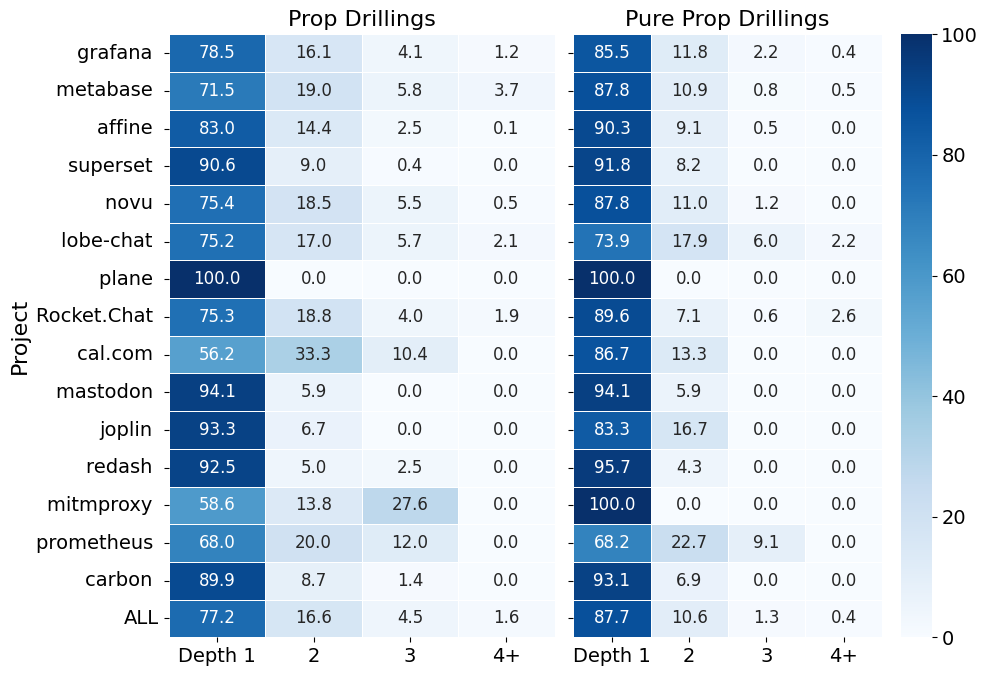

In [79]:
# Create a heatmap with depth distribution

import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np

def multiHeatMap(parts, pivotTables, columnsOrdered, sizeTuple=(2 * 5, 7)):

  heatmap_parts = parts
  all_pivot_tables = pivotTables

  # Determine global min and max for consistent color scaling across all heatmaps
  global_min_count = 0
  global_max_count = 100

  # Create a figure with subplots for each part, arranged horizontally
  # sharey=True ensures that the y-axis labels (Project) are consistent
  fig, axes = plt.subplots(1, 2, figsize=sizeTuple, sharey=True)

  # If there's only one period, axes will not be an array, so make it iterable
  if len(heatmap_parts) == 1:
      axes = [axes]

  # Define the desired order for depth distribution labels
  distr_cols_order = columnsOrdered

  for i, part in enumerate(heatmap_parts):
      ax = axes[i]
      pivot_period = all_pivot_tables[i]

      # Generate heatmap for the current part with consistent color scale
      sns.heatmap(pivot_period, annot=True, fmt=".1f", cmap="Blues", linewidths=.5,
                  vmin=global_min_count, vmax=global_max_count,
                  cbar=True if i == len(heatmap_parts) - 1 else False, # Only show colorbar for the last plot
                  ax=ax, annot_kws={'fontsize': 12, 'fontweight': 'normal'}) # Set font size for annotations
      ax.set_title(f'{part}', fontsize=16) # Set title font size to 20

      if i == len(heatmap_parts) - 1:
            # Get the colorbar object directly from the heatmap's collections
          cbar = ax.collections[0].colorbar
          cbar.ax.tick_params(labelsize=14)

      # Only show y-label for the first plot to avoid redundancy due to sharey=True
      ax.set_ylabel('Project' if i == 0 else '', fontsize=16)
      ax.set_xlabel('', fontsize=14) # Changed back to 'Model' as it's the column name
      ax.tick_params(axis='x', rotation=0, labelsize=14)
      ax.tick_params(axis='y', rotation=0, labelsize=14)
  return plt

plt = multiHeatMap(['Prop Drillings', 'Pure Prop Drillings'],
                    [pd_depth_distr_pivot, ppd_depth_distr_pivot],
                     ['1', '2', '3', '4+'])
#plt.suptitle('Depth Distribution of Prop Drillings and Pure Prop Drillings', y=1.02, fontsize=22) # Overall title
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to make space for suptitle and colorbar
plt.savefig('figure10.pdf', format='pdf')


## Compound Prop Drillings

In [80]:
# Compute compound prop drillings based on path hash
compoundPDs = df.groupby(['project', 'depth', 'pathHash', 'sloc']).size().reset_index(name='count')
compoundPDs = compoundPDs.drop(columns=['pathHash'])
compoundPDs = compoundPDs[compoundPDs['count'] > 1]

# compoundPDs count by group by project
cpd_counts = compoundPDs.groupby(['project', 'sloc']).size().reset_index(name='count')
cpd_counts = cpd_counts.sort_values(by=['sloc'], ascending=False)
# rename count columnt
cpd_counts.rename(columns={'count': 'compoundPropDrillings'}, inplace=True)
# Display the result
display(cpd_counts)

,project,sloc,compoundPropDrillings
4,grafana,696744,254
8,metabase,477532,403
1,affine,231911,166
14,superset,205589,57
10,novu,170978,266
6,lobe-chat,169644,21
11,plane,143712,3
0,Rocket.Chat,142439,91
2,cal.com,89443,10
7,mastodon,56721,58


## Refactoring Candidates

### Prop Drillings identified as refactoring candidates

In [81]:
def get_column_counts(dataframe, column_condition, count_column_name):
    filtered_df = dataframe[column_condition]
    counts = filtered_df.groupby(['project', 'sloc']).size().reset_index(name=count_column_name)
    return counts

def refCandidatesDistribution(df, baselineColumn):
  # Total candidates counts
  total_counts = get_column_counts(df, df['candidate'] == 1, 'totalCandidates')
  pd_candidates_distr = project_all_counts.merge(total_counts, on=['project', 'sloc'], how='left').fillna(0)

  # Context candidates counts
  context_counts = get_column_counts(df, df['candidateContext'] == 1, 'candidatesContext')
  pd_candidates_distr = pd_candidates_distr.merge(context_counts, on=['project', 'sloc'], how='left').fillna(0)

  # Composition candidates counts
  composition_counts = get_column_counts(df, df['candidateComposition'] == 1, 'candidatesComposition')
  pd_candidates_distr = pd_candidates_distr.merge(composition_counts, on=['project', 'sloc'], how='left').fillna(0)

  addRatioColumn(pd_candidates_distr, 'Total', 'totalCandidates', baselineColumn)
  addRatioColumn(pd_candidates_distr, 'Context', 'candidatesContext', baselineColumn)
  addRatioColumn(pd_candidates_distr, 'Composition', 'candidatesComposition', baselineColumn)

  return pd_candidates_distr[['project', 'Total', 'Context', 'Composition', 'totalCandidates', 'candidatesContext', 'candidatesComposition']]

# Calculate All row and pivot table for refactoring candidates
rc_counts = refCandidatesDistribution(df, 'propDrillings')
allCandidates = rc_counts['totalCandidates'].sum()
allContextCandidates = rc_counts['candidatesContext'].sum()
allCompositionCandidates = rc_counts['candidatesComposition'].sum()

new_row = pd.DataFrame([{'project': 'ALL',
                       'Total': ratio(allCandidates, total_prop_drillings),
                       'Context': ratio(allContextCandidates, total_prop_drillings),
                       'Composition': ratio(allCompositionCandidates, total_prop_drillings),
                         'totalCandidates': allCandidates, 'candidatesContext': allContextCandidates, 'candidatesComposition': allCompositionCandidates }])

rc_counts = pd.concat([rc_counts, new_row], ignore_index=True)
display(rc_counts)
rc_counts_pivot = rc_counts[['project', 'Total', 'Context', 'Composition']]
rc_counts_pivot = rc_counts_pivot.set_index('project')
#display(rc_counts_pivot)





,project,Total,Context,Composition,totalCandidates,candidatesContext,candidatesComposition
0,grafana,92.6,89.8,12.1,1274,1235,166.0
1,metabase,76.6,76.0,4.3,1468,1456,83.0
2,affine,64.8,64.1,5.6,545,539,47.0
3,superset,88.7,88.7,2.7,227,227,7.0
4,novu,64.0,63.8,4.0,854,851,54.0
5,lobe-chat,80.1,78.0,17.0,113,110,24.0
6,plane,42.9,28.6,21.4,6,4,3.0
7,Rocket.Chat,90.2,87.4,15.8,388,376,68.0
8,cal.com,100.0,100.0,2.1,48,48,1.0
9,mastodon,40.2,34.2,9.6,88,75,21.0


### Pure Prop Drillings identified as refactoring candidates

In [82]:
# Apply the same for pure prop drillings

rc_ppd_counts = refCandidatesDistribution(ppd_df, 'purePropDrillings')
allCandidates = rc_ppd_counts['totalCandidates'].sum()
allContextCandidates = rc_ppd_counts['candidatesContext'].sum()
allCompositionCandidates = rc_ppd_counts['candidatesComposition'].sum()

new_row = pd.DataFrame([{'project': 'ALL',
                       'Total': ratio(allCandidates, total_pure_prop_drillings),
                       'Context': ratio(allContextCandidates, total_pure_prop_drillings),
                       'Composition': ratio(allCompositionCandidates, total_pure_prop_drillings),
                         'totalCandidates': allCandidates, 'candidatesContext': allContextCandidates, 'candidatesComposition': allCompositionCandidates  }])

rc_ppd_counts = pd.concat([rc_ppd_counts, new_row], ignore_index=True)
display(rc_ppd_counts)

rc_ppd_counts_pivot = rc_ppd_counts[['project', 'Total', 'Context', 'Composition']]
rc_ppd_counts_pivot = rc_ppd_counts_pivot.set_index('project')
#display(rc_ppd_counts_pivot)

,project,Total,Context,Composition,totalCandidates,candidatesContext,candidatesComposition
0,grafana,88.6,83.8,7.6,606,573,52.0
1,metabase,75.8,74.3,4.8,638,626,40.0
2,affine,62.6,62.0,1.5,343,340,8.0
3,superset,92.5,92.5,3.4,135,135,5.0
4,novu,58.9,58.6,1.7,385,383,11.0
5,lobe-chat,80.6,78.4,16.4,108,105,22.0
6,plane,33.3,33.3,16.7,2,2,1.0
7,Rocket.Chat,80.5,77.3,6.5,124,119,10.0
8,cal.com,100.0,100.0,0.0,15,15,0.0
9,mastodon,50.0,42.2,8.8,51,43,9.0


### Heatmap: Percent of Prop Drillings and Pure Prop Drillings identified as refactoring candidates

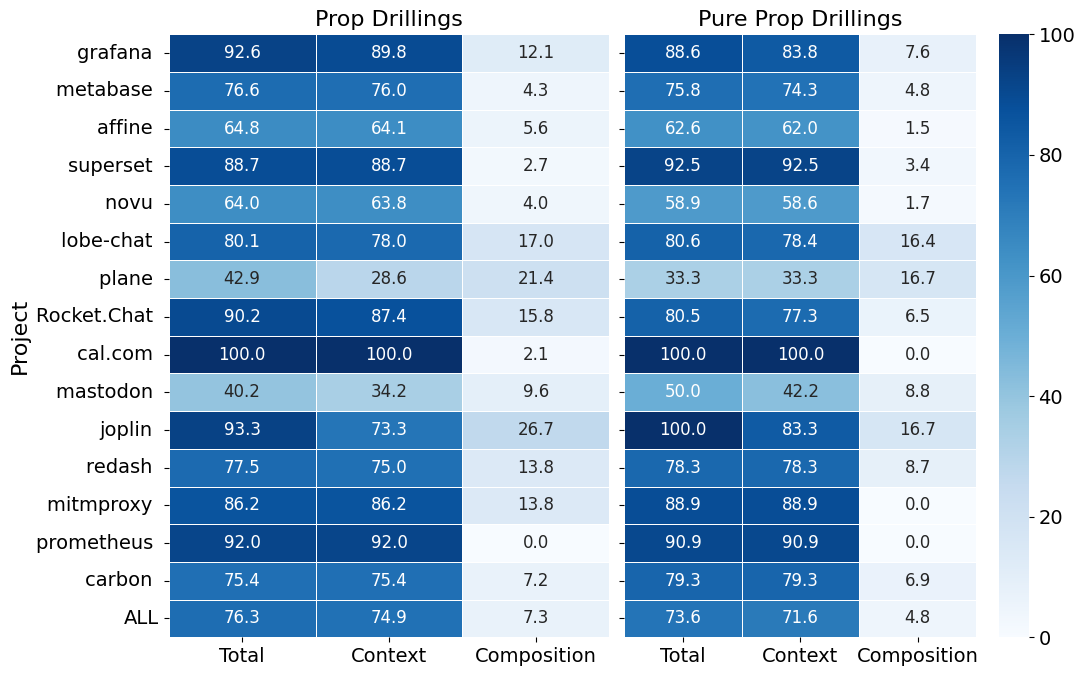

In [83]:

plt = multiHeatMap(['Prop Drillings', 'Pure Prop Drillings'],
                    [rc_counts_pivot, rc_ppd_counts_pivot],
                     ['Total', 'Context', 'Composition'], (2 * 5.5, 7))
#plt.suptitle('Depth Distribution of Prop Drillings and Pure Prop Drillings', y=1.02, fontsize=22) # Overall title
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to make space for suptitle and colorbar
plt.savefig('figure11.pdf', format='pdf')


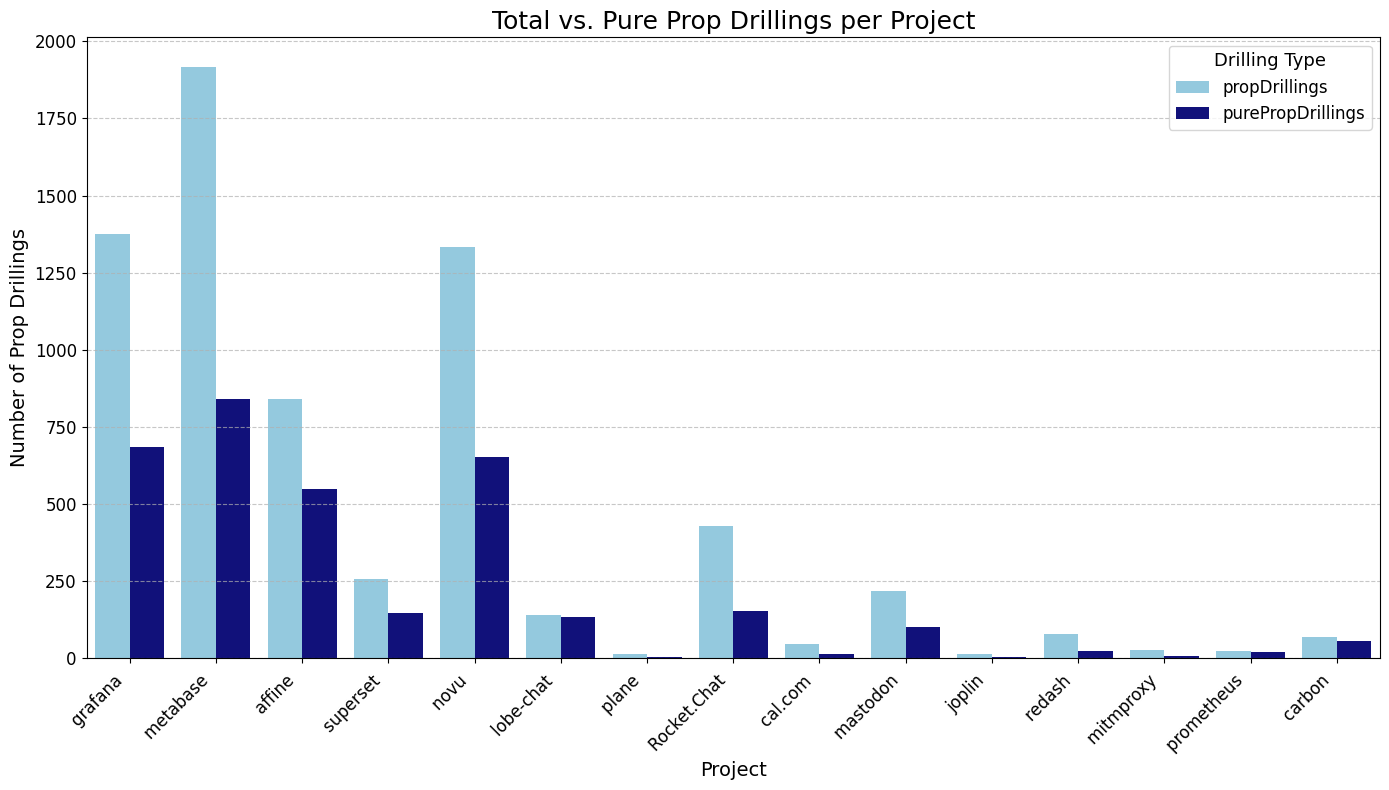

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
# Melt the DataFrame to long format for easier plotting with seaborn
df_melted = project_all_counts.melt(id_vars=['project'], value_vars=['propDrillings', 'purePropDrillings'],
                                   var_name='DrillingType', value_name='Count')

# Create the combined bar chart
plt.figure(figsize=(14, 8))
sns.barplot(x='project', y='Count', hue='DrillingType', data=df_melted, palette={'propDrillings': 'skyblue', 'purePropDrillings': 'darkblue'})

plt.title('Total vs. Pure Prop Drillings per Project', fontsize=18)
plt.xlabel('Project', fontsize=14)
plt.ylabel('Number of Prop Drillings', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Drilling Type', title_fontsize='13', fontsize='12')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()